## Checkpoint 2: Ridge Regression Implementation

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import joblib

# Folder containing the Checkpoint 1 output files
data_folder = Path.home() / "Downloads" / "Tumor_Surface_Checkpoint1_Outputs"

train = pd.read_csv(data_folder / "checkpoint1_train.csv", index_col=0)
val = pd.read_csv(data_folder / "checkpoint1_validation.csv", index_col=0)

print("Training genes:", len(train))
print("Validation genes:", len(val))
print("Training surface genes:", train["is_surface"].sum())
print("Validation surface genes:", val["is_surface"].sum())

Training genes: 1400
Validation genes: 300
Training surface genes: 175
Validation surface genes: 38


In [4]:
feature_cols = ["mean_expression", "enrichment", "expression_variability", "amplification_frequency"]

target_col = "dependency_score"

X_train = train[feature_cols]
y_train = train[target_col]

X_val = val[feature_cols]
y_val = val[target_col]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Training shape: (1400, 4)
Validation shape: (300, 4)


In [5]:
alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

results = []
models = {}

# Fit the model for each alpha and evaluate on the validation set
for alpha in alphas:
    model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler()),
                      ("ridge", Ridge(alpha=alpha))])

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)

    results.append({"alpha": alpha, "validation_MAE": mae})
    
    models[alpha] = model

tuning_results = pd.DataFrame(results)

# Display the tuning results sorted by validation MAE
display(tuning_results.sort_values("validation_MAE"))

best_alpha = tuning_results.loc[tuning_results["validation_MAE"].idxmin(), "alpha"]

# Print the best alpha and retrieve the corresponding model
best_model = models[best_alpha]

print("Best alpha:", best_alpha)

,alpha,validation_MAE
5,1000.00,0.218958
4,100.00,0.227533
6,10000.00,0.228424
3,10.00,0.229831
2,1.00,0.230097
1,0.10,0.230124
0,0.01,0.230127


Best alpha: 1000.0


In [6]:
val_predictions = best_model.predict(X_val)

# Evaluate the best model on the validation set 
def evaluate(y_true, y_pred):
    rho = spearmanr(y_true, y_pred).statistic
    return {"MAE": mean_absolute_error(y_true, y_pred), "Spearman": rho}

surface_mask = val["is_surface"].astype(bool).to_numpy()

overall_metrics = evaluate(y_val, val_predictions)
surface_metrics = evaluate(y_val.to_numpy()[surface_mask], val_predictions[surface_mask])

ridge_results = pd.DataFrame([{"Subset": "Overall", **overall_metrics},
                              {"Subset": "Surface", **surface_metrics}])

display(ridge_results)

,Subset,MAE,Spearman
0,Overall,0.218958,0.414054
1,Surface,0.184010,0.358792


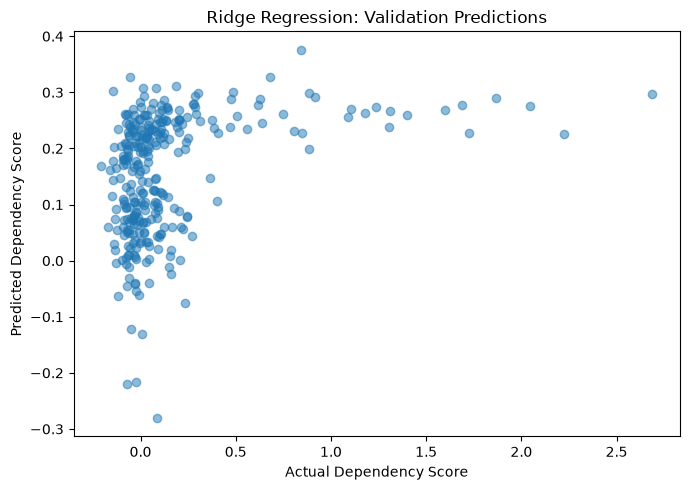

In [7]:
# Plotting the actual vs predicted dependency scores for the validation set
# NOTE: this plot shows high disprepancy between actual and predicted values
# The model is not performing well on this dataset.
plt.figure(figsize=(7, 5))
plt.scatter(y_val, val_predictions, alpha=0.5)

plt.xlabel("Actual Dependency Score")
plt.ylabel("Predicted Dependency Score")
plt.title("Ridge Regression: Validation Predictions")

plt.tight_layout()
plt.show()

In [8]:
output_folder = Path("checkpoint2_ridge_outputs")
output_folder.mkdir(exist_ok=True)

# Save the best model and results to the output folder
joblib.dump(best_model, output_folder / "ridge_model.joblib")

prediction_table = pd.DataFrame({"Gene": val.index, "Actual": y_val.to_numpy(),
                                "Predicted": val_predictions, "is_surface": surface_mask})

print(prediction_table.head(20))

# Download the predictions, metrics, and tuning results as CSV files
# prediction_table.to_csv(output_folder / "ridge_validation_predictions.csv", index=False)
# ridge_results.to_csv(output_folder / "ridge_validation_metrics.csv", index=False)
# tuning_results.to_csv(output_folder / "ridge_tuning_results.csv", index=False)

print("Ridge model and results saved.")

        Gene    Actual  Predicted  is_surface
0     SAMD11  0.100133   0.121793       False
1     RUVBL2  2.046347   0.275728       False
2      HHATL  0.042260  -0.040675       False
3    TMEM212 -0.048001  -0.121087       False
4        SP8  0.044187   0.025588       False
5   ATP6V0E2  0.002413   0.233125       False
6      OR5M9  0.074968   0.105376       False
7     CLEC4E  0.044002   0.003645       False
8     CAPN13  0.085390   0.102154       False
9      HSPG2  0.031698   0.259154       False
10  DCAF12L1 -0.133656   0.019681       False
11   TMEM123 -0.145006   0.302615       False
12     VEGFA  0.021900   0.260437       False
13     TAOK1 -0.091969   0.179890        True
14     HOXC8  0.122331   0.059417       False
15   B3GALT2 -0.062518  -0.011456        True
16     KCTD7 -0.014863   0.222243       False
17    ZBTB48  0.045660   0.235844       False
18       CRK  0.202839   0.229464        True
19     WDR41 -0.060823   0.223432       False
Ridge model and results saved.


In [9]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

from scipy.stats import spearmanr, pearsonr

val_predictions = best_model.predict(X_val)

def detailed_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Spearman": spearmanr(y_true, y_pred).statistic,
        "Pearson": pearsonr(y_true, y_pred).statistic
    }

surface_mask = val["is_surface"].astype(bool).to_numpy()

metrics_table = pd.DataFrame([
    {
        "Subset": "All validation genes",
        "Count": len(y_val),
        **detailed_metrics(y_val, val_predictions)
    },
    {
        "Subset": "Surface genes",
        "Count": surface_mask.sum(),
        **detailed_metrics(
            y_val.to_numpy()[surface_mask],
            val_predictions[surface_mask]
        )
    }
])

display(metrics_table.round(4))


,Subset,Count,MAE,RMSE,R2,Spearman,Pearson
0,All validation genes,300,0.219,0.3634,0.1166,0.4141,0.3519
1,Surface genes,38,0.184,0.2221,-0.0334,0.3588,0.3599


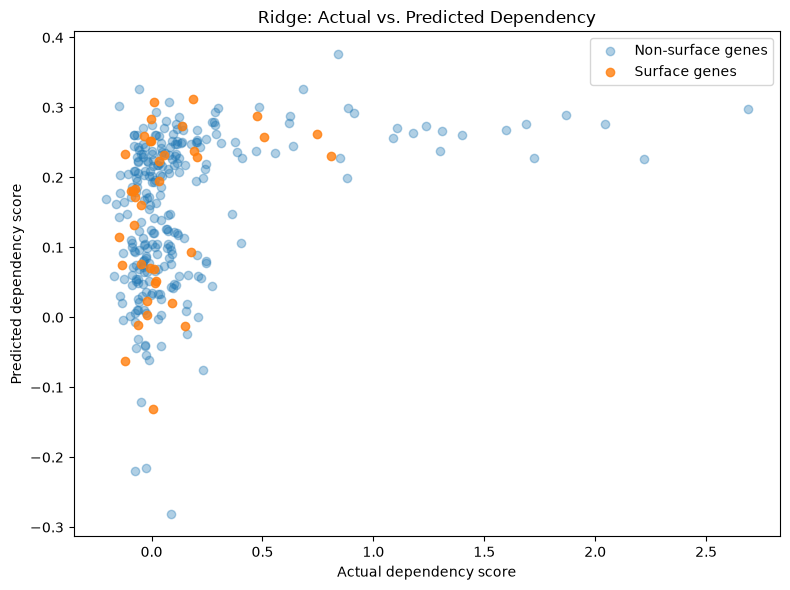

In [10]:
actual = y_val.to_numpy()

plt.figure(figsize=(8, 6))

plt.scatter(actual[~surface_mask], val_predictions[~surface_mask],
    alpha=0.35, label="Non-surface genes")

plt.scatter(actual[surface_mask], val_predictions[surface_mask],
    alpha=0.8, label="Surface genes")

limits = [min(actual.min(), val_predictions.min()),
    max(actual.max(), val_predictions.max())]

plt.xlabel("Actual dependency score")
plt.ylabel("Predicted dependency score")
plt.title("Ridge: Actual vs. Predicted Dependency")
plt.legend()
plt.tight_layout()
plt.show()


,Feature,Coefficient,Absolute coefficient
0,mean_expression,0.068017,0.068017
2,expression_variability,-0.048180,0.048180
1,enrichment,0.038065,0.038065
3,amplification_frequency,-0.001373,0.001373


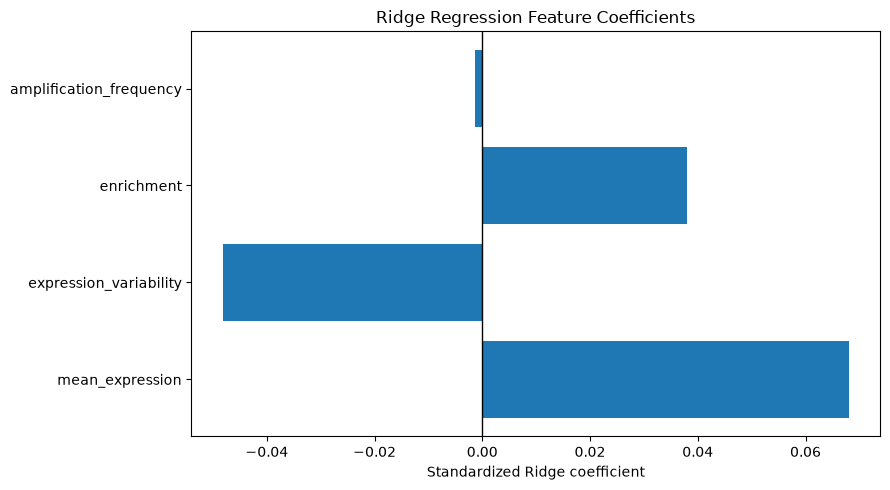

In [11]:
# Display the feature importance based on the coefficients of the Ridge regression model

coefficients = best_model.named_steps["ridge"].coef_

feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coefficients,
    "Absolute coefficient": np.abs(coefficients)
}).sort_values("Absolute coefficient", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))

plt.barh(feature_importance["Feature"], feature_importance["Coefficient"])

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Standardized Ridge coefficient")
plt.title("Ridge Regression Feature Coefficients")
plt.tight_layout()
plt.show()

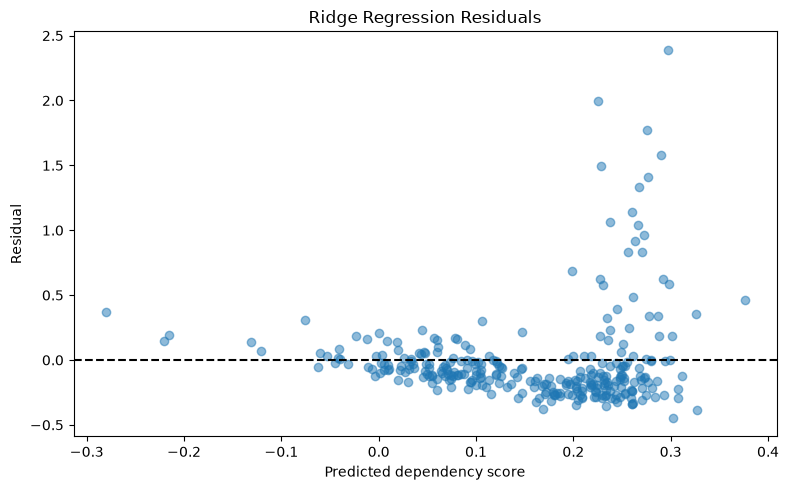

Mean residual: -0.0156
Residual standard deviation: 0.3631


In [12]:
# Plotting the residuals of the Ridge regression model on the validation set
residuals = actual - val_predictions

plt.figure(figsize=(8, 5))
plt.scatter(val_predictions, residuals, alpha=0.5)
plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Predicted dependency score")
plt.ylabel("Residual")
plt.title("Ridge Regression Residuals")
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))


In [13]:
# Display the top surface genes ranked by predicted dependency score
ranking = val.copy()

ranking["predicted_dependency"] = val_predictions
ranking["actual_dependency"] = y_val.to_numpy()
ranking["absolute_error"] = np.abs(ranking["actual_dependency"] - ranking["predicted_dependency"])

surface_ranking = (
    ranking[ranking["is_surface"].astype(bool)]
    .sort_values("predicted_dependency", ascending=False)
)

display(surface_ranking[["predicted_dependency", "actual_dependency", "absolute_error"]].head(15))


,predicted_dependency,actual_dependency,absolute_error
sample,,,
MARCKSL1,0.311734,0.186268,0.125466
ZDHHC5,0.307875,0.011439,0.296435
SLC3A2,0.287815,0.473682,0.185867
EPN1,0.283556,-0.004669,0.288225
ERBB3,0.273768,0.138888,0.134880
PFDN1,0.261365,0.746865,0.485499
TSPAN15,0.259432,-0.034055,0.293487
SNAP23,0.257288,0.505550,0.248262
SEMA4D,0.252588,-0.006933,0.259521


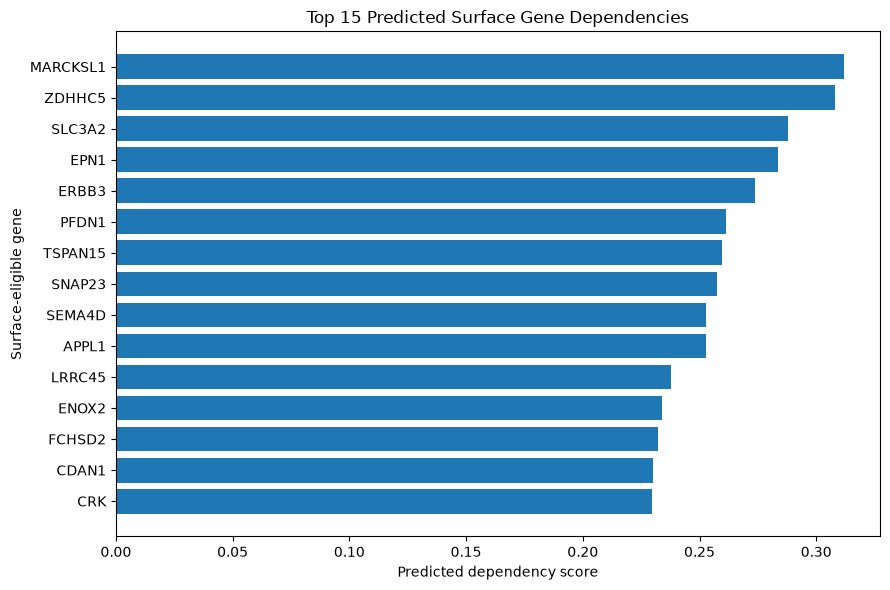

In [14]:
top15 = surface_ranking.head(15).iloc[::-1]

# Print the top 15 surface genes with their predicted and actual dependency scores
plt.figure(figsize=(9, 6))
plt.barh(top15.index.astype(str), top15["predicted_dependency"])

plt.xlabel("Predicted dependency score")
plt.ylabel("Surface-eligible gene")
plt.title("Top 15 Predicted Surface Gene Dependencies")
plt.tight_layout()
plt.show()
